# Лекция 9. Квадратурные формулы

Формула Ньютона—Лейбница даёт точный ответ одним действием, но у неё слепые
зоны: у $e^{-x^2}$, $\sin x/x$, $\ln x/x$ первообразных среди элементарных
функций просто **нет**, а иногда функция известна только таблицей измерений —
тогда первообразной не существует в принципе. Вычисляем интеграл
**квадратурной формулой** — заранее выбранной суммой значений функции с
заранее выбранными весами.

План лекции:

1. Задача численного интегрирования;
2. квадратурные формулы прямоугольников;
3. оценка формулы прямоугольников с помощью формулы Тейлора на
   симметричном отрезке $[-\tfrac h2, \tfrac h2]$;
4. семейство формул Ньютона—Котеса: простейшие формулы трапеций
   и Симпсона и их остаточные члены;
5. составные формулы трапеций и Симпсона и их остаточные члены;
6. соотношения между формулами;
7. принцип Рунге: практическое оценивание погрешности, алгоритм
   последовательного дробления шага, алгоритм Ромберга, адаптивный выбор
   шага.

> ❓ **Вопрос лекции:** сколько вычислений $f$ нужно, чтобы *гарантированно*
> получить интеграл с точностью $\varepsilon$ — и как в этом убедиться,
> не зная max $|f^{(k)}|$?

Всю лекцию помещаем в сквозной пример

$$
I = \int_0^1 e^{-x^2}\,dx = \frac{\sqrt{\pi}}{2}\,\mathrm{erf}(1)
 = 0.746824132812\ldots
$$

и время от времени сверяемся с точным значением (в реальных задачах его
не знают). Обо всех ловушках — шаг за шагом.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
plt.rcParams['figure.dpi'] = 110

# сквозной пример: f = e^(-x^2) на [0, 1]
f_star = lambda x: np.exp(-x ** 2)
I0 = math.sqrt(math.pi) / 2 * math.erf(1.0)
M2 = 2.0        # max |f''| на [0,1] (достигается при x = 0)
M4 = 12.0       # max |f''''| на [0,1]
print('сквозной пример: I = ∫₀¹ e^(−x²) dx =', I0)


сквозной пример: I = ∫₀¹ e^(−x²) dx = 0.746824132812427


## 1. 🎯 Задача численного интегрирования

Замена подынтегральной функции $f$ приближающими элементами —
ступеньками или интерполяционными многочленами — приводит к
**квадратурным формулам** (механическим квадратурам).

📖 **Определение.** **Квадратурной формулой** называется приближённое
равенство

$$
I := \int_a^b f(x)\,dx \:\approx\: \sum_{j=0}^{n} A_j\,f(x_j),
\qquad R[f] := I - \sum_{j=0}^{n} A_j f(x_j),
$$

где $x_0 < x_1 < \dots < x_n$ — **узлы**, $A_0, \dots, A_n$ — **веса**
(весовые коэффициенты). Узлы и веса выбираются *заранее*: они не зависят
ни от $f$, ни от её значений. Погрешность $R[f]$ называется
**остаточным членом**.

С формулой Ньютона—Лейбница конкурируют два препятствия:

1. **Усечение:** насколько сумма «прямоугольников» не совпала с $I$;
2. **Шум:** каждое значение $f(x_j)$ обычно известно лишь с точностью
   $\delta$ (приборная погрешность, машинный epsilon) — сумма приобретает
   искажение порядка $\delta \cdot \sum_j |A_j|$; подробно — в замечании
   об обусловленности.

Второй сквозной пример: $I = \int_1^2 \frac{\sin x}{x}\,dx$ — первообразная
(интегральный синус $\mathrm{Si}(x)$) не элементарна; а в приложениях $f$
нередко известна только в отдельных точках измерений — тогда квадратурная
формула — единственный выход.


таблица измерений f(x) = sin(x)/x (узлы с шагом h = 0.25):
  x : 1.000  1.250  1.500  1.750  2.000
  f : 0.8415  0.7592  0.6650  0.5623  0.4546
истинное значение: Si(2) − Si(1) = 0.659330
двусторонние приближения: 0.657395 < I < 0.661263


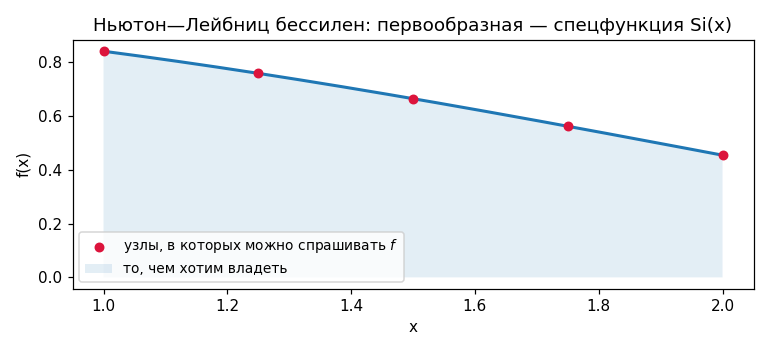

In [ ]:
f_sinc = lambda x: np.sin(x) / x

x = np.linspace(1, 2, 400)
fig, ax = plt.subplots(figsize=(7.0, 3.2))
ax.plot(x, f_sinc(x), lw=2)
nodes = np.linspace(1, 2, 5)
ax.scatter(nodes, f_sinc(nodes), s=30, zorder=5, c='crimson',
           label='узлы, в которых можно спрашивать $f$')
ax.fill_between(x, f_sinc(x), label='то, чем хотим владеть', alpha=0.12)
ax.set_title('Ньютон—Лейбниц бессилен: первообразная — спецфункция Si(x)')
ax.set_xlabel('x'); ax.set_ylabel('f(x)')
ax.legend(loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()

xi = np.linspace(1, 2, 5)
print('таблица измерений f(x) = sin(x)/x (узлы с шагом h = 0.25):')
print('  x : ' + '  '.join(f'{t:.3f}' for t in xi))
print('  f : ' + '  '.join(f'{v:.4f}' for v in f_sinc(xi)))
print('истинное значение: Si(2) − Si(1) = 0.659330')

# монотонность сразу даёт двусторонние приближения к интегралу
h2 = 0.01
xg = np.arange(1, 2 + h2 / 2, h2)
L2 = h2 * f_sinc(xg[:-1]).sum()
R2 = h2 * f_sinc(xg[1:]).sum()
print(f'двусторонние приближения: {R2:.6f} < I < {L2:.6f}')


## 2. 📏 Квадратурные формулы прямоугольников

Простые квадратурные формулы выводятся прямо из определения интеграла.
Разобьём $[a,b]$ равномерно: $x_0 = a$, $x_i = x_{i-1}+h$, $x_n = b$,
$h = (b-a)/n$; обозначим $y_i = f(x_i)$. Общая формула прямоугольников:

$$
I \approx \sum_{i=1}^{n} f(\xi_i)\,h, \qquad \xi_i \in [x_{i-1}, x_i],
$$

площадь криволинейной трапеции заменяется площадью ступенчатой фигуры из
прямоугольников. Осталось выбрать точку $\xi_i$ на каждом отрезке — три
канонических варианта:

$$
I_L(h) = h\sum_{i=1}^{n} y_{i-1}, \qquad
I_R(h) = h\sum_{i=1}^{n} y_i, \qquad
I_M(h) = h\sum_{i=1}^{n} f\!\left(x_{i-\frac12}\right),\;\;
x_{i-\frac12} = x_{i-1} + \tfrac h2 .
$$

$I_L(h)$ и $I_R(h)$ — формулы **левых** и **правых прямоугольников**.
Вместе они дают двусторонние приближения к $I$ для монотонной функции
(при росте $f$: $I_L < I < I_R$; при убывании — наоборот). $I_M(h)$ —
формула **средних прямоугольников**, или **формула средней точки**;
учитывая её априорно большую точность (см. §3), эту симметричную формулу
будем называть просто **формулой прямоугольников**.


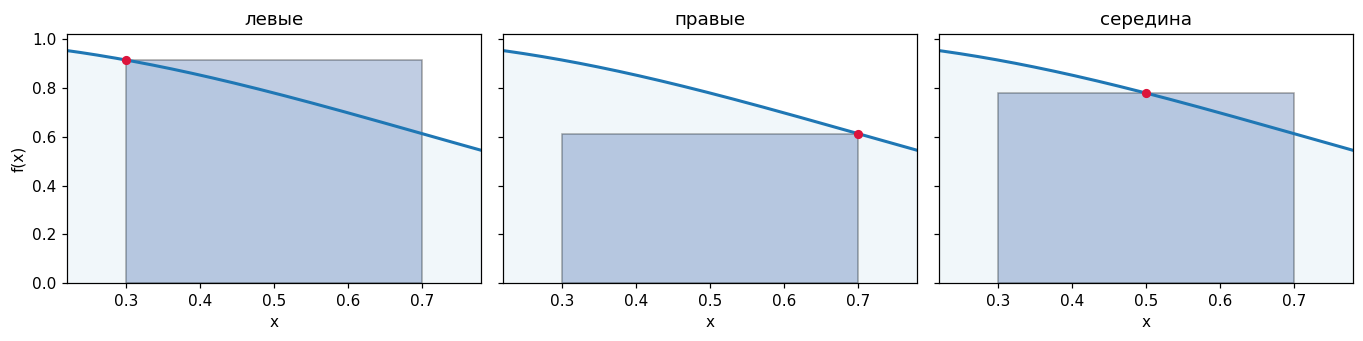

высота прямоугольника = f(xi); асимметрия выбора xi подменяет кривую на клетке


In [2]:
c, hh = 0.3, 0.4
xs = np.linspace(0, 1, 400)
fig, axes = plt.subplots(1, 3, figsize=(12.5, 3.2), sharey=True)
for ax, (name, xbar) in zip(axes, [('левые', c), ('правые', c + hh),
                                   ('середина', c + hh / 2)]):
    fb = float(f_star(np.array([xbar]))[0])
    ax.add_patch(plt.Rectangle((c, 0), hh, fb, fc='#4c72b0', alpha=0.35, ec='k'))
    ax.plot(xs, f_star(xs), lw=2)
    ax.fill_between(xs, f_star(xs), alpha=0.06)
    ax.scatter([xbar], [fb], zorder=5, c='crimson', s=25)
    ax.set_title(name)
    ax.set_xlim(c - 0.08, c + hh + 0.08)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel('x')
axes[0].set_ylabel('f(x)')
plt.tight_layout(); plt.show()

print('высота прямоугольника = f(xi); асимметрия выбора xi подменяет кривую на клетке')


In [ ]:
def rect_left(f, a, b, n):
    h = (b - a) / n
    return h * f(np.linspace(a, b - h, n)).sum()

def rect_right(f, a, b, n):
    h = (b - a) / n
    return h * f(np.linspace(a + h, b, n)).sum()

def rect_mid(f, a, b, n):
    h = (b - a) / n
    return h * f(a + h * (np.arange(n) + 0.5)).sum()

print(f"{'n':>4} | {'I−L':>10} {'I−R':>10} | {'|I−M|':>10} {'× при h/2':>10}")
prev = None
for n in [4, 8, 16, 32, 64]:
    eL = I0 - rect_left(f_star, 0, 1, n)
    eR = I0 - rect_right(f_star, 0, 1, n)
    eM = abs(rect_mid(f_star, 0, 1, n) - I0)
    shrink = '—' if prev is None else f'×{prev / eM:.1f}'
    print(f'{n:4d} | {eL:10.4e} {eR:10.4e} | {eM:10.4e} {shrink:>10}')
    prev = eM

print('убывающая f: двусторонние приближения L > I > R выполняются:',
      f'{rect_left(f_star, 0, 1, 64) > I0} и {rect_right(f_star, 0, 1, 64) < I0}')
print('ошибка середины убывает в 4 раза при h/2 (порядок h²), левых и правых — лишь вдвое (порядок h)')


   n |        I−L        I−R |      |I−M|  × при h/2
   4 | -7.5175e-02 8.2855e-02 | 1.9230e-03          —
   8 | -3.8549e-02 4.0466e-02 | 4.7945e-04       ×4.0
  16 | -1.9514e-02 1.9993e-02 | 1.1978e-04       ×4.0
  32 | -9.8170e-03 9.9368e-03 | 2.9940e-05       ×4.0
  64 | -4.9235e-03 4.9534e-03 | 7.4846e-06       ×4.0
убывающая f: двусторонние приближения L > I > R выполняются: True и True
ошибка середины убывает в 4 раза при h/2 (порядок h²), левых и правых — лишь вдвое (порядок h)


## 3. ⚡ Оценка формулы прямоугольников с помощью формулы Тейлора

Полученные из определения интеграла правила не отвечают на вопрос, каким
брать шаг $h$ для гарантированной точности $\varepsilon$. Положим оценку на
другую основу. Пусть $f \in C^2$; рассмотрим интеграл по симметричному
отрезку $[-\tfrac h2, \tfrac h2]$ при малом $h > 0$:

$$
I_0 := \int_{-h/2}^{h/2} f(x)\,dx .
$$

По формуле Тейлора (с остаточным членом в форме Лагранжа)

$$
f(x) = f(0) + f'(0)\,x + \tfrac12\, f''(\tilde\xi)\,x^2 .
$$

Подставляя и интегрируя почленно (нечётное слагаемое $f'(0)\,x$
интегрируется в нуль):

$$
I_0 = h\,f(0) + \frac{h^3}{24}\, f''(\tilde\xi).
$$

Слагаемое $h\,f(0)$ — приближение к $I_0$ по формуле прямоугольников в
случае всего одного отрезка; $\dfrac{h^3}{24} f''(\tilde\xi)$ — остаточный
член (локальная погрешность) этой формулы.

Выполнив произвольное разбиение $[a,b]$ на $n$ частей, заменим каждый
отрезок $[x_{i-1}, x_i]$ отрезком той же длины с центром симметрии и
применим формулу к каждому слагаемому аддитивности интеграла. Остаточные
члены суммируются; применение обобщённой теоремы о среднем к сумме даёт
остаточный член (глобальную погрешность) формулы прямоугольников:

$$
r_N(h) := I - I_M(h) = \frac{(b-a)\,h^2}{24}\, f''(\xi_N),
\qquad \xi_N \in (a,b).
$$

При увеличении $n$ ошибка убывает пропорционально **квадрату шага**; для
формул левых и правых прямоугольников ошибка убывает лишь по **линейному**
закону.


## 4. 💡 Формулы Ньютона—Котеса: трапеций и Симпсона

Подстановка в интеграл вместо $f$ её **интерполяционного многочлена
Лагранжа** $P_n$ степени $n$ по равномерным узлам $x_j = a + jh$ и точное
интегрирование многочлена приводит к семейству **формул Ньютона—Котеса**:

$$
\int_a^b P_n(x)\,dx = \sum_{j=0}^{n} A_j\, y_j,
\qquad A_j := \int_a^b \ell_j(x)\,dx,
$$

где $\ell_j$ — базисные многочлены Лагранжа. Веса — интегралы от базисных
многочленов: от $f$ они не зависят. Замена $x = a + ht$ сводит всё к
отрезку $[0, n]$:

$$
c_j := \frac{A_j}{h} = \int_0^{n} \tilde\ell_j(t)\,dt,
$$

и для равномерной сетки числа $c_j$ зависят только от степени $n$; они
называются **коэффициентами Котеса**. Свойства: $c_0 + \dots + c_n = 1$
(точность на константах) и $c_j = c_{n-j}$ (симметрия).

Вычислим коэффициенты точно — рациональной арифметикой, решая систему
$\sum_j c_j\, t_j^k = \int_0^n t^k\,dt = \dfrac{n^{k+1}}{k+1}$, $k = 0..n$:


In [5]:
from fractions import Fraction as Frac

def cotes_weights(n):
    t = [Frac(i) for i in range(n + 1)]
    A = [[t[j] ** k for j in range(n + 1)] for k in range(n + 1)]
    b = [Frac(n ** (k + 1), k + 1) for k in range(n + 1)]
    for col in range(n + 1):
        piv = max(range(col, n + 1), key=lambda r: abs(A[r][col]))
        A[col], A[piv] = A[piv], A[col]
        b[col], b[piv] = b[piv], b[col]
        for r in range(n + 1):
            if r != col and A[r][col]:
                g = A[r][col] / A[col][col]
                A[r] = [v - g * w for v, w in zip(A[r], A[col])]
                b[r] -= g * b[col]
    return [b[j] / A[j][j] for j in range(n + 1)]

def fmt_weights(w):
    den = math.lcm(*[c.denominator for c in w])
    return '  '.join(str(int(c * den)) for c in w)

print('коэффициенты Котеса (общий знаменатель подписан):')
for n in [1, 2, 3, 4, 5]:
    w = cotes_weights(n)
    den = math.lcm(*[c.denominator for c in w])
    note = '   ← трапеции' if n == 1 else ('   ← Симпсона' if n == 2 else '')
    print(f'n={n}:  ' + fmt_weights(w) + f'  (делить на {den})' + note)


коэффициенты Котеса (общий знаменатель подписан):
n=1:  1  1  (делить на 2)   ← трапеции
n=2:  1  4  1  (делить на 3)   ← Симпсона
n=3:  3  9  9  3  (делить на 8)
n=4:  14  64  24  64  14  (делить на 45)
n=5:  95  375  250  250  375  95  (делить на 288)


Первые члены семейства получают имена:

**Простейшая формула трапеций** ($n = 1$, прямая через два узла):

$$
\int_{x_0}^{x_1} f\,dx \approx \frac h2 (y_0 + y_1),
\qquad r_T = -\frac{h^3}{12}\, f''(\xi).
$$

**Простейшая формула Симпсона** ($n = 2$, парабола через три узла):

$$
\int_{x_0}^{x_2} f\,dx \approx \frac h3 (y_0 + 4 y_1 + y_2),
\qquad r_S = -\frac{h^5}{90}\, f^{(4)}(\xi).
$$

Остаточные члены оцениваются так же, как в §3, но без симметрии клетки;
знак «−» для гладких $f$ устойчив. Далее по первому интерполяционному
многочлену Ньютона строится вся таблица семейства:

| $k$ | $B_k$ | веса $a_j$ | остаточный член |
|---|---|---|---|
| 1 | $1/2$ | $1,\,1$ | $-\tfrac{h^3}{12} f''(\xi)$ |
| 2 | $1/3$ | $1,\,4,\,1$ | $-\tfrac{h^5}{90} f^{(4)}(\xi)$ |
| 3 | $3/8$ | $1,\,3,\,3,\,1$ | $-\tfrac{3h^5}{80} f^{(4)}(\xi)$ |
| 4 | $2/45$ | $7,\,32,\,12,\,32,\,7$ | $-\tfrac{8h^7}{945} f^{(6)}(\xi)$ |
| 5 | $5/288$ | $19,\,75,\,50,\,50,\,75,\,19$ | $-\tfrac{275 h^7}{12096} f^{(6)}(\xi)$ |

Формула семейства: $\displaystyle\int_{x_0}^{x_k} f\,dx \approx
B_k\, h \sum_j a_j\, y_j$ на клетке $[x_0, x_k]$ (длина $kh$).
Причина, по которой на практике никогда не поднимаются выше $k = 5$
— обусловленность 


In [6]:
# таблица семейства и проверка остаточных членов на мономиалах x^m,
# где m — порядок производной в остатке, h = 1
Bk = {1: (1, 2), 2: (1, 3), 3: (3, 8), 4: (2, 45), 5: (5, 288)}
Ak = {1: [1, 1], 2: [1, 4, 1], 3: [1, 3, 3, 1], 4: [7, 32, 12, 32, 7],
      5: [19, 75, 50, 50, 75, 19]}
predk = {1: -1 / 12 * 2, 2: -1 / 90 * 24, 3: -3 / 80 * 24,
         4: -8 / 945 * 720, 5: -275 / 12096 * 720}

print('проверка остаточных членов на мономиалах (h = 1):')
for k in Bk:
    p = {1: 2, 2: 4, 3: 4, 4: 6, 5: 6}[k]
    Bn, Bd = Bk[k]
    x = np.arange(k + 1, dtype=float)
    y = x ** p
    approx = Bn / Bd * float(np.dot(Ak[k], y))
    exact = k ** (p + 1) / (p + 1)
    r = exact - approx
    print(f'  k={k}, x^{p}: ∫ = {exact:9.4f},  формула = {approx:9.4f},'
          f'  r = {r:+8.4f},  предсказан {predk[k]:+8.4f}')
print('все остаточные члены совпадают с табличными;'
      ' формула (2/45)·(7,32,12,32,7) точна на x⁵')


проверка остаточных членов на мономиалах (h = 1):
  k=1, x^2: ∫ =    0.3333,  формула =    0.5000,  r =  -0.1667,  предсказан  -0.1667
  k=2, x^4: ∫ =    6.4000,  формула =    6.6667,  r =  -0.2667,  предсказан  -0.2667
  k=3, x^4: ∫ =   48.6000,  формула =   49.5000,  r =  -0.9000,  предсказан  -0.9000
  k=4, x^6: ∫ = 2340.5714,  формула = 2346.6667,  r =  -6.0952,  предсказан  -6.0952
  k=5, x^6: ∫ = 11160.7143,  формула = 11177.0833,  r = -16.3690,  предсказан -16.3690
все остаточные члены совпадают с табличными; формула (2/45)·(7,32,12,32,7) точна на x⁵


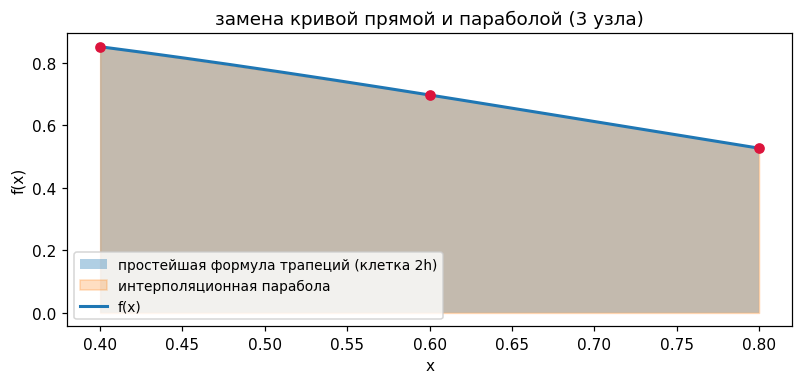

частичный интеграл           I = 0.278017017
простейшая формула трапеций  T = 0.275887243   ошибка 2.13e-03
простейшая формула Симпсона  S = 0.278009434   ошибка 7.58e-06


In [7]:
# простейшие формулы трапеций и Симпсона на одной клетке [0.4, 0.8], h = 0.2
xa, xb = 0.4, 0.8
hs = (xb - xa) / 2
xi3 = np.array([xa, xa + hs, xb])
yn3 = f_star(xi3)

x = np.linspace(xa, xb, 400)
xk = np.linspace(xa, xb, 200)
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.fill_between(xk, np.interp(xk, xi3, yn3), alpha=0.35,
                label='простейшая формула трапеций (клетка 2h)')
P_interp = np.poly1d(np.polyfit(xi3, yn3, 2))
ax.fill_between(x, P_interp(x), alpha=0.25, color='tab:orange',
                label='интерполяционная парабола')
ax.plot(x, f_star(x), lw=2, label='f(x)')
ax.scatter(xi3, yn3, s=36, zorder=5, c='crimson')
ax.set_title('замена кривой прямой и параболой (3 узла)')
ax.set_xlabel('x'); ax.set_ylabel('f(x)'); ax.legend(loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()

I_part = math.sqrt(math.pi) / 2 * (math.erf(xb) - math.erf(xa))
T_one = hs * (yn3[0] + yn3[2])
S_one = hs / 3 * (yn3[0] + 4 * yn3[1] + yn3[2])
print(f'частичный интеграл           I = {I_part:.9f}')
print(f'простейшая формула трапеций  T = {T_one:.9f}   ошибка {abs(T_one - I_part):.2e}')
print(f'простейшая формула Симпсона  S = {S_one:.9f}   ошибка {abs(S_one - I_part):.2e}')


простейшая формула Симпсона: 0.747180429, точное 0.746824133, ошибка 3.56e-04
граница остатка M4·h⁵/90 (h = 0.5 — половина длины клетки): 4.2e-03


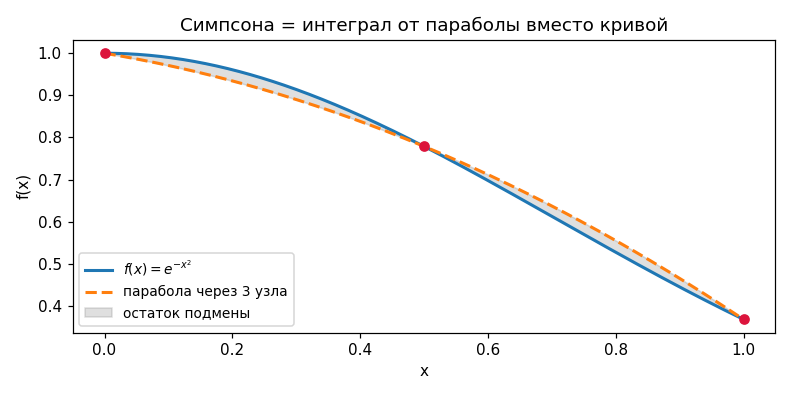

In [ ]:
# простейшая формула Симпсона (k = 2) на сквозном примере [0, 1]
nodes = np.array([0.0, 0.5, 1.0])
yn = f_star(nodes)
P2 = np.poly1d(np.polyfit(nodes, yn, 2))

x = np.linspace(0, 1, 400)
fig, ax = plt.subplots(figsize=(7.2, 3.6))
ax.plot(x, f_star(x), lw=2, label=r'$f(x)=e^{-x^2}$')
ax.plot(x, P2(x), lw=2, ls='--', color='tab:orange', label='парабола через 3 узла')
ax.fill_between(x, f_star(x), P2(x), alpha=0.25, color='gray', label='остаток подмены')
ax.scatter(nodes, yn, s=36, zorder=5, c='crimson')
ax.set_title('Симпсона = интеграл от параболы вместо кривой')
ax.set_xlabel('x'); ax.set_ylabel('f(x)'); ax.legend(loc='lower left', fontsize=9)
plt.tight_layout(); plt.show()

S0 = 0.5 / 3 * (yn[0] + 4 * yn[1] + yn[2])
err0 = abs(float(S0) - I0)
print(f'простейшая формула Симпсона: {float(S0):.9f}, точное {I0:.9f}, ошибка {err0:.2e}')
print(f'граница остатка M4·h⁵/90 (h = 0.5 — половина длины клетки): {M4 * 0.5**5 / 90:.1e}')


## 5. 🧮 Составные формулы трапеций и Симпсона

Простейшие формулы на одной клетке редко дают нужную точность. Вместо
подъёма степени применяют **составные** формулы: разбиваем $[a,b]$ на $n$
отрезков, применяем простейшую формулу на каждом отрезке и суммируем.

Для $f \in C^2$ — **составная формула трапеций**:

$$
I_T(h) := h\left(\frac{y_0}{2} + y_1 + \dots + y_{n-1} + \frac{y_n}{2}\right),
\qquad r_T = I - I_T(h) = -\frac{(b-a)\,h^2}{12}\, f''(\xi);
$$

для $f \in C^4$ и чётного $n = 2m$, с суммами нечётных
$\sigma_1 = y_1 + y_3 + \dots + y_{2m-1}$ и чётных
$\sigma_2 = y_2 + y_4 + \dots + y_{2m-2}$ индексов — **составная формула
Симпсона**:

$$
I_S(h) := \frac h3 (y_0 + 4\sigma_1 + 2\sigma_2 + y_n),
\qquad r_S = I - I_S(h) = -\frac{(b-a)\,h^4}{180}\, f^{(4)}(\xi).
$$

Составные формулы проще, устойчивее и дешевле простейших формул больших
степеней, поэтому на практике правила длины шага применяют к формулам
только низких порядков.

⚠️ **Пример с гарантиями (сквозной пример).**
$|f''(x)| \le M_2 = 2$ и $|f^{(4)}(x)| \le M_4 = 12$ на $[0,1]$, поэтому
$|r_T| \le \tfrac{h^2}{6}$ и $|r_S| \le \tfrac{h^4}{15}$: чтобы достичь
$\varepsilon = 10^{-6}$, трапециям нужно $h \le 2.4\cdot 10^{-3}$
($n > 405$), Симпсону — $h \le 0.062$ ($n > 16$): в ~25 раз меньше
вычислений $f$.


In [8]:
def comp_trap(f, a, b, n):
    h = (b - a) / n
    y = f(np.linspace(a, b, n + 1))
    return h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])

def comp_simp(f, a, b, n):
    h = (b - a) / n
    y = f(np.linspace(a, b, n + 1))
    return h / 3 * (y[0] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum() + y[-1])

print(f"{'n':>4} | {'|I−T|':>10} {'h²/6':>9} | {'|I−S|':>10} {'h⁴/15':>9} | {'новых f':>8}")
prev = None
for n in [4, 8, 16, 32, 64, 128]:
    h = 1 / n
    eT = abs(comp_trap(f_star, 0, 1, n) - I0)
    eS = abs(comp_simp(f_star, 0, 1, n) - I0)
    nf = '—' if prev is None else str(n - prev)
    print(f'{n:4d} | {eT:10.4e} {h**2/6:9.1e} | {eS:10.4e} {h**4/15:9.1e} | {nf:>8}')
    prev = n

S16 = comp_simp(f_star, 0, 1, 16)
print(f'Симпсона, n=16: значение {S16:.13f}, ошибка {abs(S16 - I0):.2e} ≤ ε = 1e−6')


   n |      |I−T|      h²/6 |      |I−S|     h⁴/15 |  новых f
   4 | 3.8400e-03   1.0e-02 | 3.1247e-05   2.6e-04 |        —
   8 | 9.5852e-04   2.6e-03 | 1.9877e-06   1.6e-05 |        4
  16 | 2.3954e-04   6.5e-04 | 1.2462e-07   1.0e-06 |        8
  32 | 5.9878e-05   1.6e-04 | 7.7946e-09   6.4e-08 |       16
  64 | 1.4969e-05   4.1e-05 | 4.8725e-10   4.0e-09 |       32
 128 | 3.7423e-06   1.0e-05 | 3.0454e-11   2.5e-10 |       64
Симпсона, n=16: значение 0.7468242574357, ошибка 1.25e-07 ≤ ε = 1e−6


### ⚖️ Замечание об обусловленности: почему не поднимаются выше

Чем выше порядок $O(h^p)$, тем быстрее падает усечение, но тем сильнее
усиливается шум: искажения значений $f$ на $\delta$ умножаются на веса —
а сумма $|A_j|$ растёт с ростом степени и убыванием шага. Кроме того,
формулы высоких степеней требуют высокой гладкости $f$: обещанные порядки
теряются при разрыве производных (§7, «осторожность на негладких f»).
Посмотрим на «пол» погрешности, ниже которого не уйти, — на сквозном
примере, где $f$ известна с точностью машинного epsilon:


значения f известны с точностью δ = 2e-16 (машинный epsilon)
     n | усечение Симпсона | шум ~ δ·(b−a)
   256 |         1.903e-12 |       2.2e-16
  1024 |         7.327e-15 |       2.2e-16
  4096 |         1.110e-16 |       2.2e-16
 16384 |         0.000e+00 |       2.2e-16
усечение = шум при h ≈ (15δ)^0.25 = 2.4e-04,  n ≈ 4164
Симпсона: ниже уровня δ·(b−a) ≈ 2.2e−16 погрешность не опустить —
значения f точнее этого просто не бывают; трапециям шум мешает при несравнимо меньших n


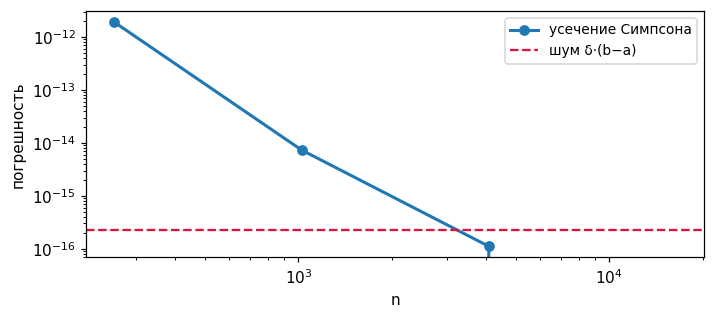

In [9]:
delta = 2.22e-16    # машинный epsilon
print(f'значения f известны с точностью δ = {delta:.0e} (машинный epsilon)')
print(f"{'n':>6} | {'усечение Симпсона':>17} | {'шум ~ δ·(b−a)':>13}")
ns = [256, 1024, 4096, 16384]
truncs = []
for n in ns:
    eS = abs(comp_simp(f_star, 0, 1, n) - I0)
    truncs.append(eS)
    print(f'{n:6d} | {eS:17.3e} | {delta:13.1e}')

h_eff = (float(15 * delta)) ** 0.25
print(f'усечение = шум при h ≈ (15δ)^0.25 = {h_eff:.1e},  n ≈ {math.ceil(1 / h_eff / 2) * 2}')
print('Симпсона: ниже уровня δ·(b−a) ≈ 2.2e−16 погрешность не опустить —')
print('значения f точнее этого просто не бывают; трапециям шум мешает при несравнимо меньших n')

fig, ax = plt.subplots(figsize=(6.6, 3.0))
ax.loglog(ns, truncs, 'o-', lw=2, label='усечение Симпсона')
ax.axhline(delta, color='crimson', ls='--', lw=1.5, label='шум δ·(b−a)')
ax.set_xlabel('n'); ax.set_ylabel('погрешность')
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout(); plt.show()


## 6. 🔗 Соотношения между формулами

Формулы связаны точными равенствами. Полусумма левых и правых:

$$
I_T(h) = \tfrac12 \bigl(I_L(h) + I_R(h)\bigr).
$$

Симпсона собирается из трапеции и середины на клеточном шаге $2h$:

$$
I_S(h) = \tfrac13\, I_T(2h) + \tfrac23\, I_M(2h).
$$

Наконец, вычисляя из последней связи и из поведения ошибки трапеций
($r_T = O(h^2)$):

$$
I_S(h) = I_T(h) + \frac{1}{3}\,\bigl(I_T(h) - I_T(2h)\bigr),
$$

где добавка $\tfrac13 (I_T(h) - I_T(2h))$ называется **поправкой
Ричардсона**. Она превращает таблицу трапеций в формулу Симпсона:
$I_S(h)$ становится **без единого нового вычисления $f$** — все три
величины уже посчитаны. Все тождества проверяем численно (до машинного
epsilon).


In [ ]:
n = 8
h = 1 / n
y = f_star(np.linspace(0, 1, n + 1))
L = h * y[:-1].sum()
R = h * y[1:].sum()
T = h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])
S = h / 3 * (y[0] + y[-1] + 4 * y[1:-1:2].sum() + 2 * y[2:-1:2].sum())

ym = f_star(h * (2 * np.arange(n // 2) + 1))
M2h = 2 * h * ym.sum()
T2 = 2 * h * (0.5 * y[0] + y[2:-1:2].sum() + 0.5 * y[-1])

print(f'n = {n}:')
print(f'тождество I_T = (I_L + I_R)/2            : разность {T - (L + R) / 2:.1e}')
print(f'тождество I_S = (2·I_M(2h) + I_T(2h))/3  : разность {S - (2 * M2h + T2) / 3:.1e}')
rich = T + (T - T2) / 3
print(f'поправка Ричардсона  I_T(h) + (I_T(h) − I_T(2h))/3 = {rich:.13f}')
print(f'формула Симпсона     I_S(h)                      = {S:.13f}')
print(f'разность                                = {abs(S - rich):.1e}  (машинный epsilon)')


n = 8:
тождество I_T = (I_L + I_R)/2            : разность 0.0e+00
тождество I_S = (2·I_M(2h) + I_T(2h))/3  : разность 0.0e+00
поправка Ричардсона  I_T(h) + (I_T(h) − I_T(2h))/3 = 0.7468261205275
формула Симпсона     I_S(h)                      = 0.7468261205275
разность                                = 1.1e-16  (машинный epsilon)


## 7. 🧠 Правило Рунге: практическое оценивание погрешности

Резюмируем выводы §§3–5 о порядке убывания ошибки:

$$
|r| \approx c\,h^p ,
$$

где $p = 2$ для трапеций и прямоугольников, $p = 4$ для Симпсона.
Как только $p$ известен, сравнение двух расчётов с шагами $h$ и $h/2$
даёт **правило Рунге** — практическую оценку погрешности и уточнённое
значение:

$$
\frac{R(h/2)}{R(h)} \approx 2^{-p}
\;\Longrightarrow\;
R(h) \approx \frac{I_{h/2} - I_h}{2^p - 1}, \qquad
I \approx I_{h/2} + \frac{I_{h/2} - I_h}{2^p - 1}.
$$

Вторую часть формулы называют **уточнением по Ричардсону**; для трапеций
оно совпадает с формулой Симпсона (§6).

**Критерий согласованности.** Оценка по правилу Рунге достоверна лишь,
когда базовые приближения уже близки и ошибка вышла на асимптотику
$c\,h^p$. Применяется контроль:

$$
\rho_h = \frac{I_h - I_{2h}}{I_{h/2} - I_h} \approx 2^p :
$$

если $\rho_h$ далек от $2^p$ — расчёты ещё не согласованы, и оценка
недостоверна (типичная причина — негладкая $f$).

**Алгоритм последовательного дробления шага.** Вычисляем интеграл по
правилу трапеций при последовательно удваивающемся числе отрезков
$n = 1, 2, 4, 8, \dots$; каждый шаг требует только $\tfrac n2$ новых
вычислений $f$ (узлы старой сетки переиспользуются):

$$
I_T^{(2n)} = \tfrac12\, I_T^{(n)} + h_{new}\sum f\!\left(\text{новые середины}\right),
$$

и останавливаемся, когда $\bigl|I_T^{(2n)} - I_T^{(n)}\bigr|/3 \le
\varepsilon$ (множитель $1/3$ — та же поправка Ричардсона). Априорная
гарантия из §5: достаточно $n \ge \lceil \sqrt{6\,M_2/\varepsilon}\rceil$
— двойной счёт заодно проверяет, что $\varepsilon$ достигнуто, не требуя
знания $M_2$ вовсе.

**Алгоритм Ромберга.** Соединяет дробление шага с каскадом поправок
Ричардсона: первая колонка таблицы — трапеции при $n = 1, 2, 4, \dots$,
каждая следующая колонка — уточнение Ричардсона предыдущей; диагональ
даёт последовательность приближений порядка $h^{2m}$ при росте $m$.

**Адаптивный выбор шага.** Глобальный шаг строится по самой сложной части
$f$; удваивая подразделение отрезка только там, где локальная оценка
ошибки велика, получаем все преимущества дробления без лишних вычислений
(пример — в конце секции).

⚠️ **Осторожность на негладких $f$.** Если реальный порядок меньше
заявленного (разрывы производных, острые пики), правило Рунге и критерий
согласованности дают неверную оценку. Проверка на негладкой функции —
в конце секции.


In [10]:
print(f"{'n':>4} {'h':>8} | {'|I−T|':>10} {'Runge-оц.':>10} {'ρ_h':>7}")
vals = []
for n in [8, 16, 32, 64, 128, 256, 512]:
    h = 1 / n
    Tn = comp_trap(f_star, 0, 1, n)
    if len(vals) < 2:
        print(f'{n:4d} {h:8.5f} | {I0 - Tn:10.4e} {"—":>10} {"—":>7}')
    else:
        runge = (Tn - vals[-1]) / 3
        rho = (vals[-1] - vals[-2]) / (Tn - vals[-1])
        print(f'{n:4d} {h:8.5f} | {I0 - Tn:10.4e} {runge:10.4e} {rho:7.3f}')
    vals.append(Tn)
print('ρ_h → 2² = 4: правило Рунге честно прогнозирует погрешность трапеций')

print(f"{'n':>4} {'h':>8} | {'|I−S|':>10} {'Runge-оц.':>10} {'ρ_h':>7}")
vals = []
for n in [8, 16, 32, 64, 128, 256]:
    h = 1 / n
    Sn = comp_simp(f_star, 0, 1, n)
    if len(vals) < 2:
        print(f'{n:4d} {h:8.5f} | {I0 - Sn:10.4e} {"—":>10} {"—":>7}')
    else:
        runge = (Sn - vals[-1]) / 15
        rho = (vals[-1] - vals[-2]) / (Sn - vals[-1])
        print(f'{n:4d} {h:8.5f} | {I0 - Sn:10.4e} {runge:10.4e} {rho:7.3f}')
    vals.append(Sn)
print('ρ_h → 2⁴ = 16; напечатанные Runge-оценки при n → ∞ приближаются к |I−S|')


   n        h |      |I−T|  Runge-оц.     ρ_h
   8  0.12500 | 9.5852e-04          —       —
  16  0.06250 | 2.3954e-04          —       —
  32  0.03125 | 5.9878e-05 5.9886e-05   4.002
  64  0.01562 | 1.4969e-05 1.4970e-05   4.000
 128  0.00781 | 3.7423e-06 3.7423e-06   4.000
 256  0.00391 | 9.3557e-07 9.3557e-07   4.000
 512  0.00195 | 2.3389e-07 2.3389e-07   4.000
ρ_h → 2² = 4: правило Рунге честно прогнозирует погрешность трапеций
   n        h |      |I−S|  Runge-оц.     ρ_h
   8  0.12500 | -1.9877e-06          —       —
  16  0.06250 | -1.2462e-07          —       —
  32  0.03125 | -7.7946e-09 -7.7886e-09  15.947
  64  0.01562 | -4.8725e-10 -4.8715e-10  15.988
 128  0.00781 | -3.0454e-11 -3.0453e-11  15.997
 256  0.00391 | -1.9035e-12 -1.9034e-12  15.999
ρ_h → 2⁴ = 16; напечатанные Runge-оценки при n → ∞ приближаются к |I−S|


In [ ]:
# последовательное дробление шага: трапеции, требуемая точность eps = 1e-9
eps = 1e-9
print(f'последовательное дробление шага (трапеции, ε = {eps:.0e}):')
print(f"{'n':>6} {'|Runge-оценка|':>14} {'факт |I−T|':>11} {'новых f':>8}")
n = 1
T_prev = 0.5 * (f_star(np.array([0.0]))[0] + f_star(np.array([1.0]))[0])
print(f'{n:6d} {"—":>14} {abs(T_prev - I0):11.2e} {2:8d}')
while True:
    n2 = 2 * n
    h_new = 1 / n2
    x_new = h_new * (2 * np.arange(n) + 1)
    T_new = 0.5 * T_prev + h_new * f_star(x_new).sum()
    runge = abs(T_new - T_prev) / 3
    print(f'{n2:6d} {runge:14.2e} {abs(T_new - I0):11.2e} {n:8d}')
    if runge <= eps:
        break
    n = n2
    T_prev = T_new
apr = math.ceil(math.sqrt(M2 / (12 * eps)))
print(f'априорная оценка: n ≥ ⌈√(M2·(b−a)²/12·ε)⌉ = {apr} (гарантия, а не алгоритм)')
print(f'двойной счёт не требует знания M2 вовсе: остановка |Δ|/3 ≤ ε,'
      f' факт |I−T| = {abs(T_new - I0):.2e} ≤ ε')
print('каждый шаг добавляет лишь n новых вычислений f — узлы переиспользуются')


последовательное дробление шага (трапеции, ε = 1e-09):
     n |Runge-оценка|  факт |I−T|  новых f
     1              —    6.29e-02        2
     2       1.58e-02    1.55e-02        1
     4       3.87e-03    3.84e-03        2
     8       9.61e-04    9.59e-04        4
    16       2.40e-04    2.40e-04        8
    32       5.99e-05    5.99e-05       16
    64       1.50e-05    1.50e-05       32
   128       3.74e-06    3.74e-06       64
   256       9.36e-07    9.36e-07      128
   512       2.34e-07    2.34e-07      256
  1024       5.85e-08    5.85e-08      512
  2048       1.46e-08    1.46e-08     1024
  4096       3.65e-09    3.65e-09     2048
  8192       9.14e-10    9.14e-10     4096
априорная оценка: n ≥ ⌈√(M2·(b−a)²/12·ε)⌉ = 12910 (гарантия, а не алгоритм)
двойной счёт не требует знания M2 вовсе: остановка |Δ|/3 ≤ ε, факт |I−T| = 9.14e-10 ≤ ε
каждый шаг добавляет лишь n новых вычислений f — узлы переиспользуются


In [ ]:
# таблица Ромберга: дробление шага + каскад поправок Ричардсона
def trap_seq(nn):
    hh = 1 / nn
    yy = f_star(np.linspace(0, 1, nn + 1))
    return hh * (0.5 * yy[0] + yy[1:-1].sum() + 0.5 * yy[-1])

rows = [[trap_seq(2 ** i)] for i in range(6)]
for kk in range(1, 6):
    for m in range(kk, 6):
        rows[m].append((4 ** kk * rows[m][kk - 1] - rows[m - 1][kk - 1]) / (4 ** kk - 1))

print('таблица Ромберга: R_{m,i} — i поправок Ричардсона над I_T(2^m)')
for m, row in enumerate(rows):
    print('  m=%d  ' % m + ' '.join(f'{v:.10f}' for v in row))
print(f'вычислений f: только {2**5 + 1} для всей таблицы (= узлы последней трапеции)')
diag = rows[5]
print(f'диагональ: ошибка R_(5,5) = {abs(diag[-1] - I0):.2e}'
      f'  против ошибки I_T(32) = {abs(diag[0] - I0):.2e}')


таблица Ромберга: R_{m,i} — i поправок Ричардсона над I_T(2^m)
  m=0  0.6839397206
  m=1  0.7313702518 0.7471804289
  m=2  0.7429840978 0.7468553798 0.7468337098
  m=3  0.7458656148 0.7468261205 0.7468241699 0.7468240185
  m=4  0.7465845968 0.7468242574 0.7468241332 0.7468241326 0.7468241331
  m=5  0.7467642547 0.7468241406 0.7468241328 0.7468241328 0.7468241328 0.7468241328
вычислений f: только 33 для всей таблицы (= узлы последней трапеции)
диагональ: ошибка R_(5,5) = 1.83e-13  против ошибки I_T(32) = 5.99e-05


In [ ]:
# негладкая f: заявленные порядки теряются
kink = 0.41
g_kink = lambda x: np.abs(x - kink)
I_kink = (kink ** 2 + (1 - kink) ** 2) / 2
print(f'негладкая f: f(x) = |x − {kink}| (разрыв первой производной)')
print(f"{'n':>6} {'|I−T|':>10} {'× при h/2':>10} | {'|I−S|':>10} {'× при h/2':>10}")
t_prev, s_prev = None, None
for n in [4, 8, 16, 32, 64]:
    eT = abs(comp_trap(g_kink, 0, 1, n) - I_kink)
    eS = abs(comp_simp(g_kink, 0, 1, n) - I_kink)
    rT = '—' if t_prev is None else f'×{t_prev / eT:.1f}'
    rS = '—' if s_prev is None else f'×{s_prev / eS:.1f}'
    print(f'{n:6d} {eT:10.4e} {rT:>10} | {eS:10.4e} {rS:>10}')
    t_prev, s_prev = eT, eS
print('факторы при h/2 нерегулярны: асимптотики нет, правило Рунге недостоверно —')
print('проверяйте гладкость f, прежде чем верить степеням 2ᵖ')


негладкая f: f(x) = |x − 0.41| (разрыв первой производной)
     n      |I−T|  × при h/2 |      |I−S|  × при h/2
     4 1.4400e-02          — | 6.9000e-03          —
     8 3.1500e-03       ×4.6 | 6.0000e-04      ×11.5
    16 9.6250e-04       ×3.3 | 2.3333e-04       ×2.6
    32 1.0312e-04       ×9.3 | 1.8333e-04       ×1.3
    64 4.4531e-05       ×2.3 | 2.5000e-05       ×7.3
факторы при h/2 нерегулярны: асимптотики нет, правило Рунге недостоверно —
проверяйте гладкость f, прежде чем верить степеням 2ᵖ


In [ ]:
# адаптивный выбор шага: узкий пик; формула Симпсона на субинтервалах
A, c0 = 100.0, 250000.0
f_bump = lambda x: 1.0 + A * np.exp(-c0 * (x - 0.4) ** 2)
I_bump = 1.0 + A * math.sqrt(math.pi / c0)
eps = 1e-6

cache = {}
def F(x):
    t = float(x)
    if t not in cache:
        cache[t] = float(f_bump(t))
    return cache[t]

def simpsons_cell_rule(a, b):
    m = (a + b) / 2
    return (b - a) / 6 * (F(a) + 4 * F(m) + F(b))

def adaptive_simpson_cell(a0, b0, tol, box):
    total = 0.0
    stack = [(a0, b0, simpsons_cell_rule(a0, b0))]
    while stack:
        a, b, whole = stack.pop()
        mid = (a + b) / 2
        lo = simpsons_cell_rule(a, mid)
        hi = simpsons_cell_rule(mid, b)
        box[0] += 2
        if abs(lo + hi - whole) <= 15 * tol:
            total += lo + hi
        else:
            stack.append((a, mid, lo))
            stack.append((mid, b, hi))
    return total

def adaptive_simpson(a, b, eps0, k0=8):
    # разведочная сетка из k0 отрезков, tol на клетку — eps0/k0
    pts = np.linspace(a, b, k0 + 1)
    box = [k0 + 1 + k0]
    total = 0.0
    for i in range(k0):
        total += adaptive_simpson_cell(pts[i], pts[i + 1], eps0 / k0, box)
    return total, box[0]

V, nodes_a = adaptive_simpson(0, 1, eps)
print(f'адаптивная Симпсона (разведочная сетка из 8 отрезков): {V:.9f}')
print(f'  узлов {nodes_a}, ошибка {abs(V - I_bump):.2e} ≤ ε = {eps:.0e}')

def unit_simp(n):
    h_ = 1 / n
    ks = np.arange(n // 2)
    return h_ / 3 * (f_bump(0) + f_bump(1)
                     + 4 * f_bump(h_ * (2 * ks + 1)).sum()
                     + 2 * f_bump(2 * h_ * ks + 2 * h_).sum())

n, S_prev = 8, unit_simp(8)
while abs(unit_simp(2 * n) - S_prev) / 15 > eps:
    n = 2 * n
    S_prev = unit_simp(n)
n_u = 2 * n
print(f'равномерная по тому же критерию: n = {n_u} → {n_u + 1} узлов,'
      f' ошибка {abs(unit_simp(n_u) - I_bump):.2e}')
print(f'шаг подстраивается под локальную сложность f: {nodes_a} узлов против'
      f' {n_u + 1} — ×{round((n_u + 1) / nodes_a)} (и при этом точнее)')


адаптивная Симпсона (разведочная сетка из 8 отрезков): 1.354491369
  узлов 145, ошибка 5.99e-07 ≤ ε = 1e-06
равномерная по тому же критерию: n = 65536 → 65537 узлов, ошибка 1.02e-05
шаг подстраивается под локальную сложность f: 145 узлов против 65537 — ×452 (и при этом точнее)
